# Customer Churn Prediction Using Machine Learning

<sub>**Supervised Learning · Binary Classification · IBM Telco Customer Churn Dataset**</sub>

---

## Project Overview

This project develops and evaluates machine learning models to predict whether a telecommunications customer is likely to leave the company. The analysis uses customer demographics, account information, subscribed services, and billing characteristics.

| Project Detail | Description |
|---|---|
| **Problem type** | Binary classification |
| **Learning type** | Supervised learning |
| **Dataset** | IBM Telco Customer Churn |
| **Target variable** | `Churn` |
| **Target classes** | `Yes` (churn) · `No` (no churn) |

### 1.1 Problem Statement

Predict whether an existing telecommunications customer will churn using demographic information, account details, subscribed services, and billing characteristics, so that customer-retention teams can identify customers at risk and prioritize appropriate retention actions.

### 1.2 Project Objectives

- Explore the dataset and understand customer churn patterns.
- Identify customer characteristics associated with churn.
- Clean and prepare the data for machine learning.
- Build and compare classification models.
- Evaluate model performance using appropriate classification metrics.
- Examine incorrect predictions and identify opportunities for improvement.

### 1.3 Machine Learning Approach

This is a supervised binary classification task. The model learns from historical customer records and predicts one of two outcomes: churn or no churn.

## 2. Importing Required Libraries

Import the libraries used for data manipulation, numerical computation, visualization, preprocessing, model training, and evaluation.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# Dataset splitting and cross-validation
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

# Baseline model
from sklearn.dummy import DummyClassifier

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score
)

# Display settings
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

# Reproducibility
RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


## 3. Loading the Dataset

Load the IBM Telco Customer Churn dataset from a CSV file into a Pandas DataFrame. The dataset contains customer demographics, subscribed services, account details, and billing information.

In [2]:
# Load the Kaggle dataset
df = pd.read_csv("../dataset/Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 4. Initial Dataset Inspection

Inspect the dataset dimensions, column names, data types, and sample records to understand its structure.

In [3]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

Dataset Shape: (7043, 21)


In [4]:
# First five records
display(df.head())


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Column names
print("\nDataset Columns:")
print(df.columns.tolist())



Dataset Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [6]:
# Dataset information
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null

## 5. Data Quality Assessment

Check the dataset for missing values and duplicate records before proceeding with analysis and preprocessing.

In [7]:
# Missing values summary
print("Missing Values Summary:")
print(df.isnull().sum())


Missing Values Summary:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [8]:
# Duplicate records
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


## 6. Target Variable Analysis

Examine the distribution of the target variable, `Churn`, using counts, percentages, and a visualization. This also helps identify class imbalance.

In [9]:
# Count churn categories
print("Churn Counts:")
print(df['Churn'].value_counts())

Churn Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [10]:
# Calculate percentages
print("\nChurn Percentages:")
churn_percentages = (df['Churn'].value_counts(normalize=True)*100).round(2)
print(churn_percentages)


Churn Percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


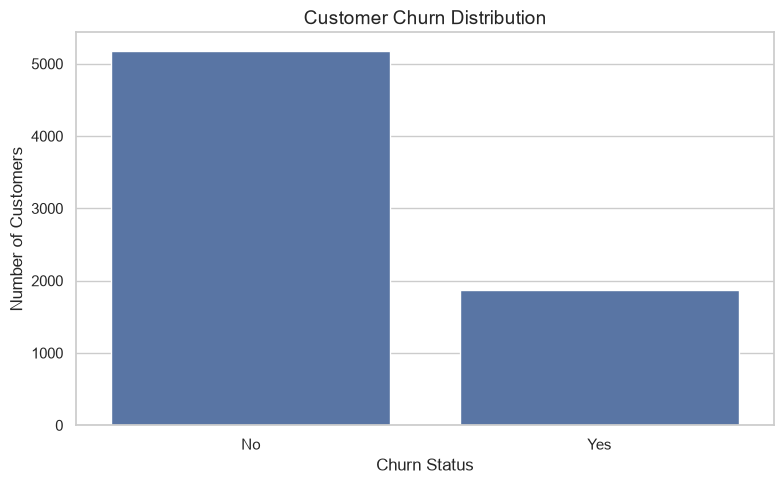

In [11]:
# Visualize churn distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution', fontsize=14)
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

## 7. Data Type Correction and Missing-Value Handling

The `TotalCharges` column is initially stored as text. Convert it to a numeric data type so it can be used in numerical analysis and preprocessing.

- Blank entries are converted to missing values during numeric conversion.
- The converted column is checked for missing values.
- The preprocessing pipeline later imputes missing numerical values using the training data.

In [12]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("Updated Data Type:", df['TotalCharges'].dtype)
print("Missing TotalCharges Values:", df['TotalCharges'].isnull().sum())

Updated Data Type: float64
Missing TotalCharges Values: 11


In [13]:
print("Missing Values After Conversion:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values After Conversion:
TotalCharges    11
dtype: int64

Total Missing Values: 11


## 8. Exploratory Data Analysis (EDA)

Explore customer characteristics and investigate patterns that may be associated with churn. The following visualizations examine tenure, contract type, and billing behaviour.

### 8.1 Customer Tenure Distribution

Examine how long customers have remained with the telecommunications company.

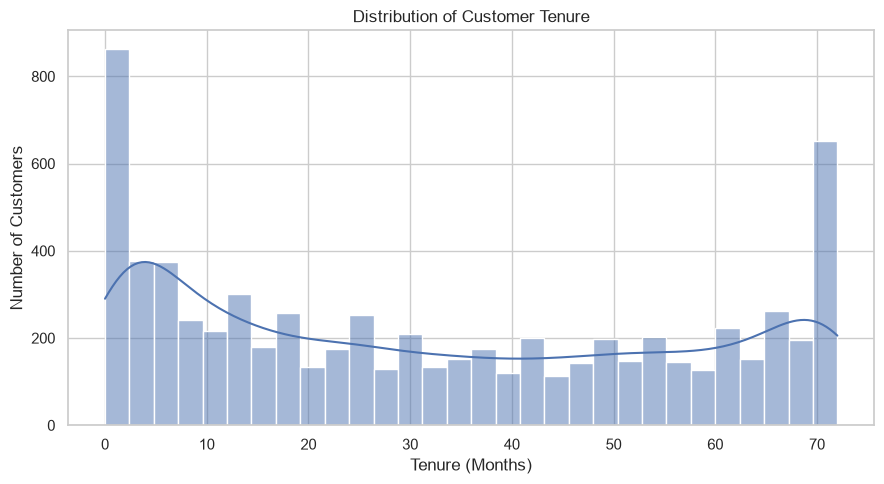

In [14]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='tenure', bins=30, kde=True)

plt.title('Distribution of Customer Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

### 8.2 Contract Type vs. Customer Churn

Compare churn counts across contract types to investigate whether contract duration is associated with customer churn.

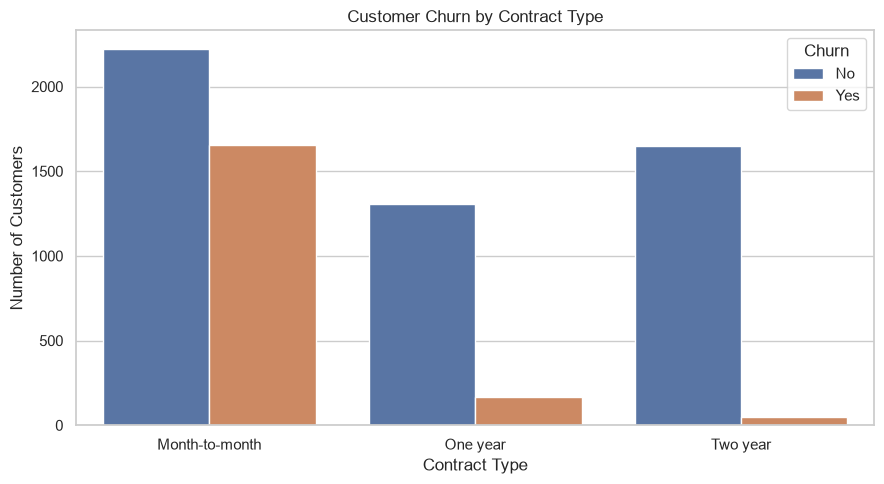

In [15]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x='Contract', hue='Churn')

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.tight_layout()
plt.show()

### 8.3 Monthly Charges vs. Customer Churn

Compare monthly charges for customers who churned and those who remained with the company.

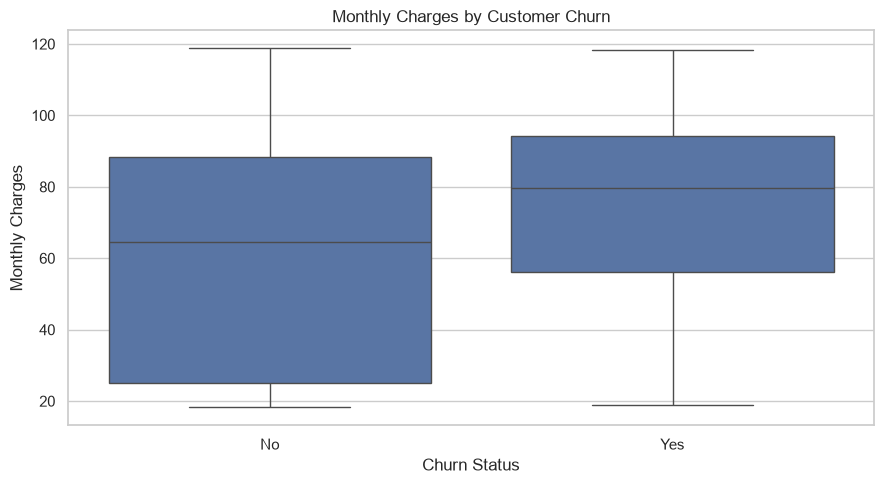

In [16]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x='Churn', y='MonthlyCharges')

plt.title('Monthly Charges by Customer Churn')
plt.xlabel('Churn Status')
plt.ylabel('Monthly Charges')

plt.tight_layout()
plt.show()

### 8.4 Customer Tenure vs. Churn

Compare customer tenure across churn categories to investigate whether newer customers are more likely to leave.

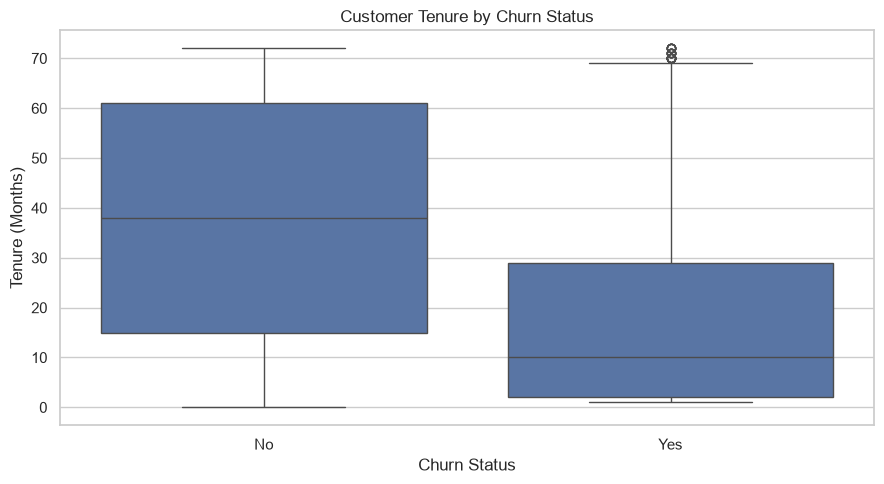

In [17]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x='Churn', y='tenure')

plt.title('Customer Tenure by Churn Status')
plt.xlabel('Churn Status')
plt.ylabel('Tenure (Months)')

plt.tight_layout()
plt.show()

### 8.5 EDA Summary

The exploratory analysis provides an initial view of customer behaviour and churn patterns.

- Tenure distributions help describe how long customers remain with the company.
- Contract comparisons help investigate the relationship between commitment length and churn.
- Monthly-charge comparisons explore billing differences between churned and retained customers.
- Tenure comparisons help assess whether shorter customer relationships are associated with churn.

These observations guide the subsequent feature analysis. They describe associations in this dataset and do not, by themselves, establish causation.

## 9. Feature Analysis and Selection

Investigate how individual customer attributes relate to churn. Categorical features are compared using churn rates, while numerical features are examined through descriptive statistics and visualizations.

All available predictor features are initially retained; model-based evaluation is used later to assess predictive performance.

### 9.1 Categorical Feature Churn Rates

Visualize churn percentages across categories to identify customer groups with relatively higher or lower churn rates.

C:\Users\sajja\AppData\Local\Temp\ipykernel_2104\1350018606.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include='object').columns.tolist()


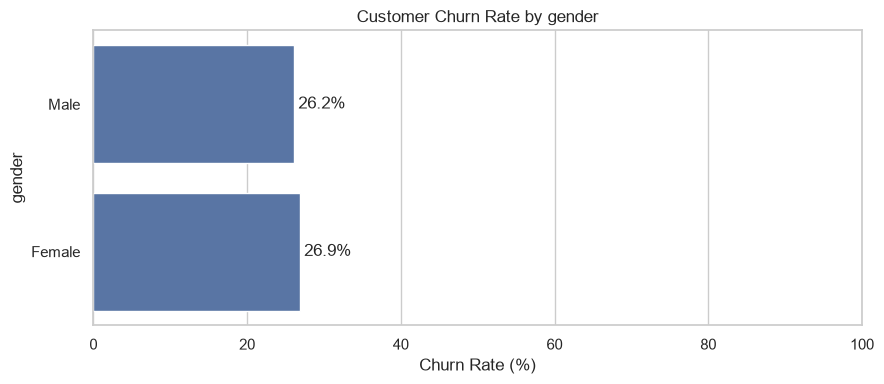

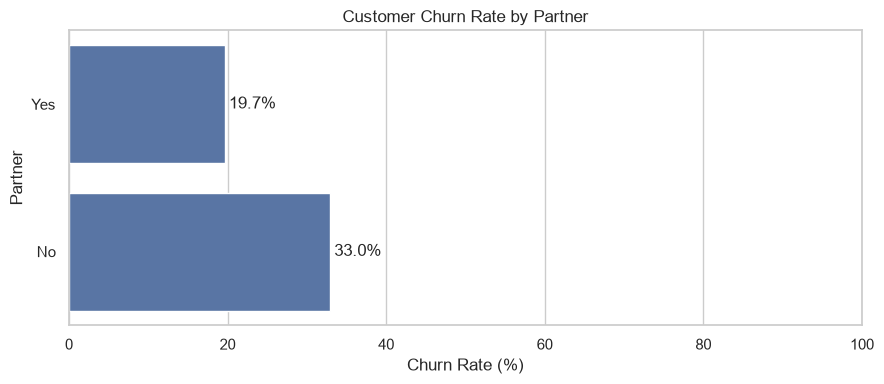

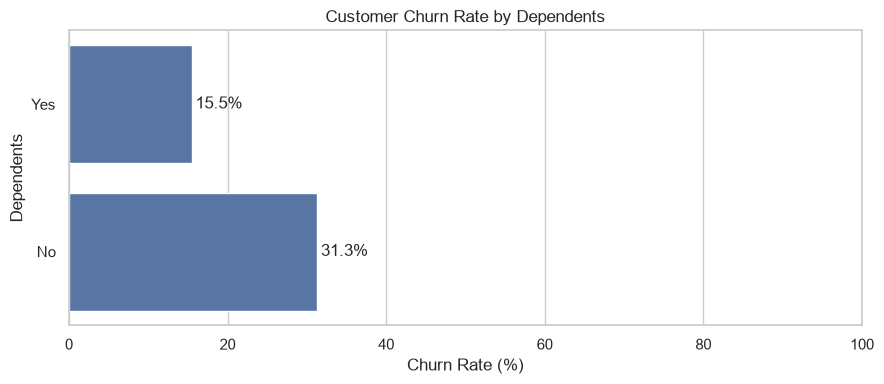

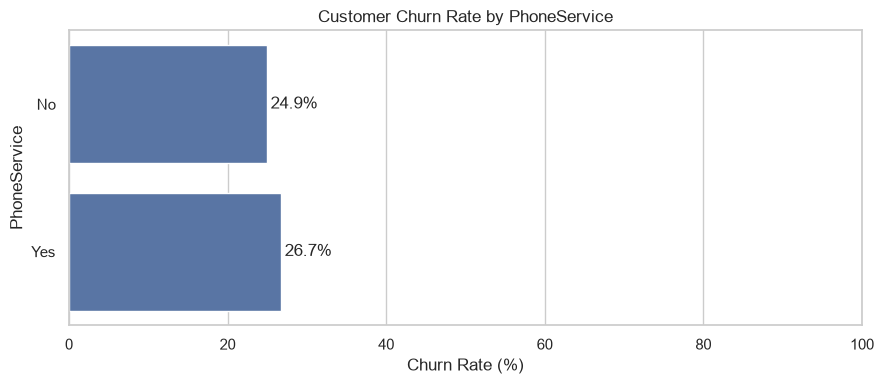

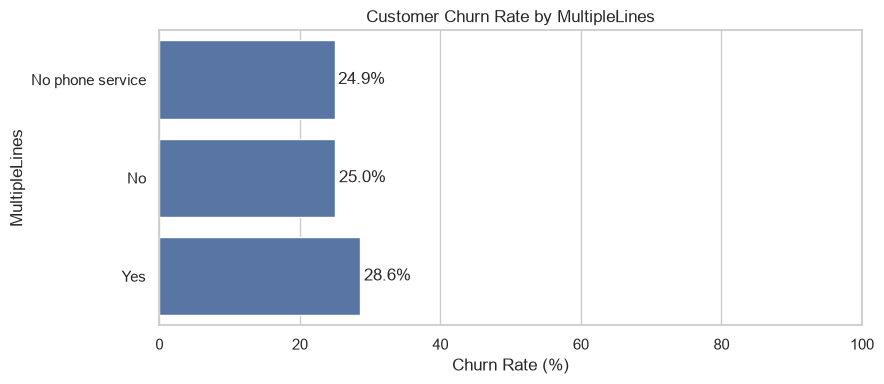

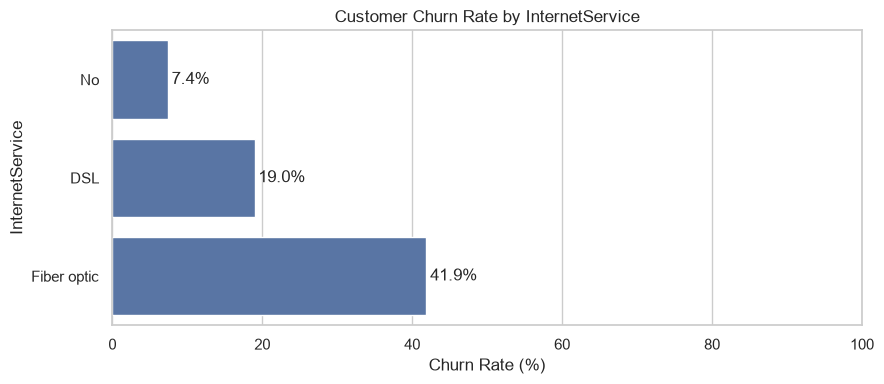

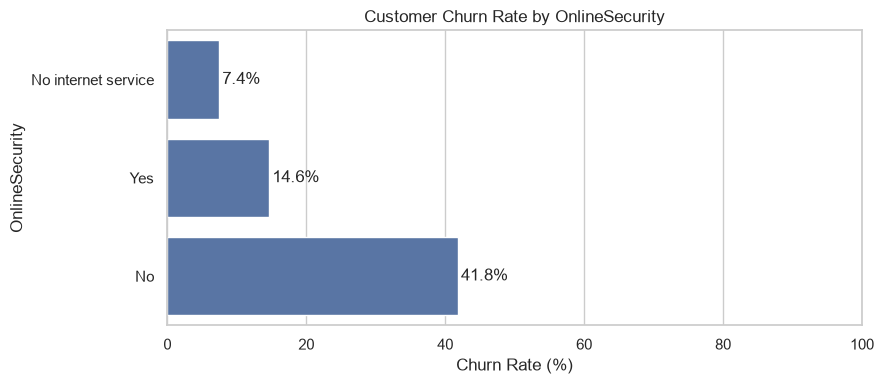

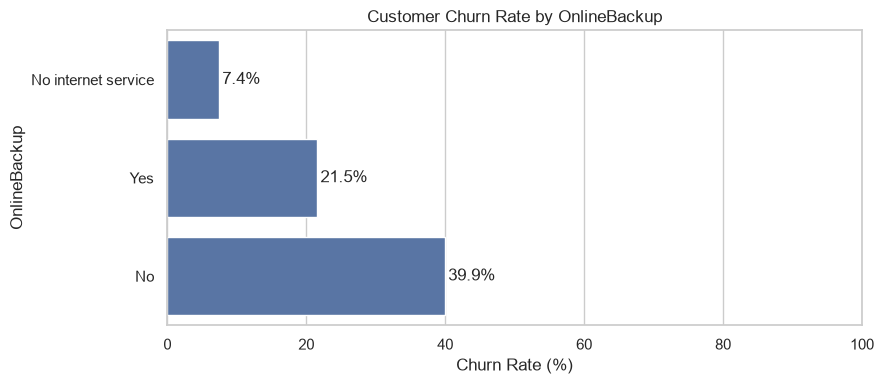

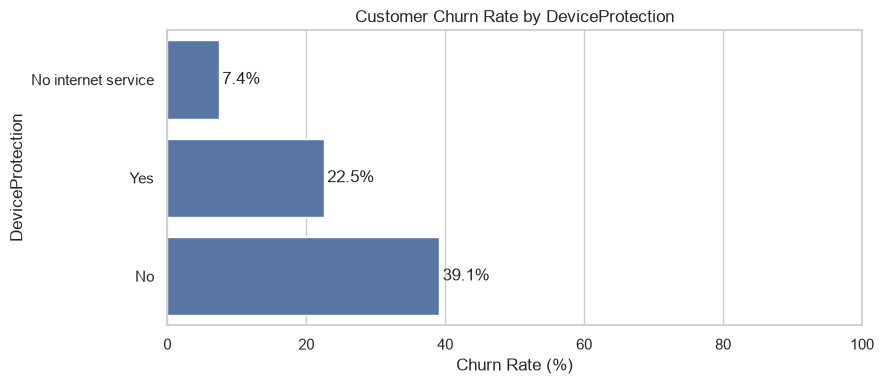

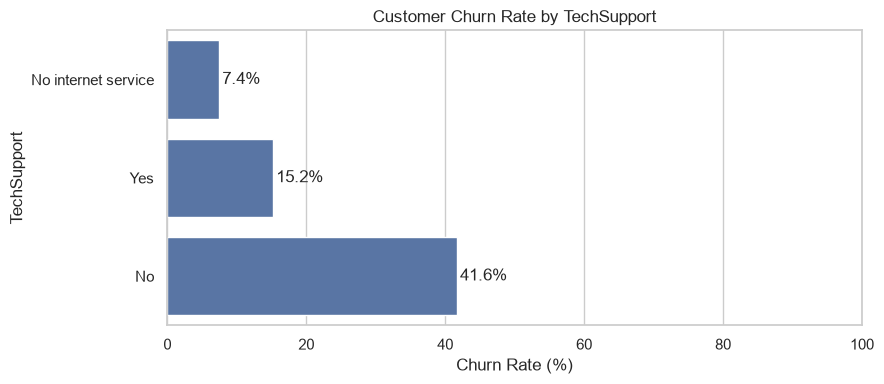

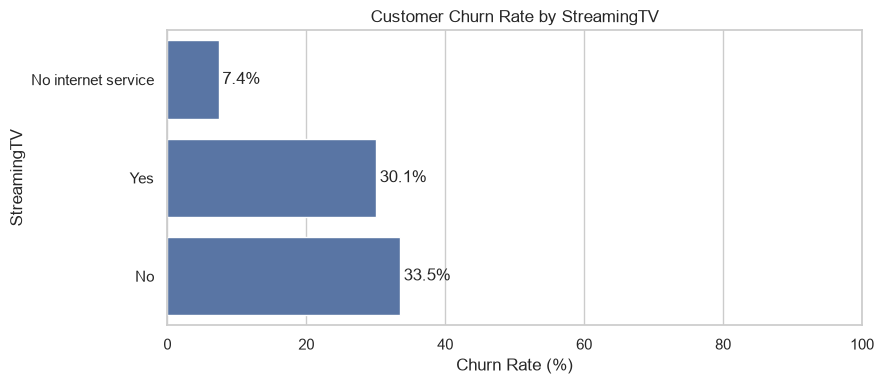

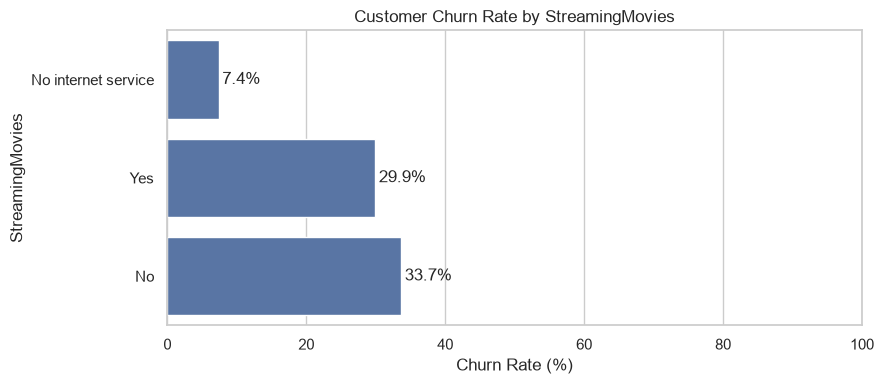

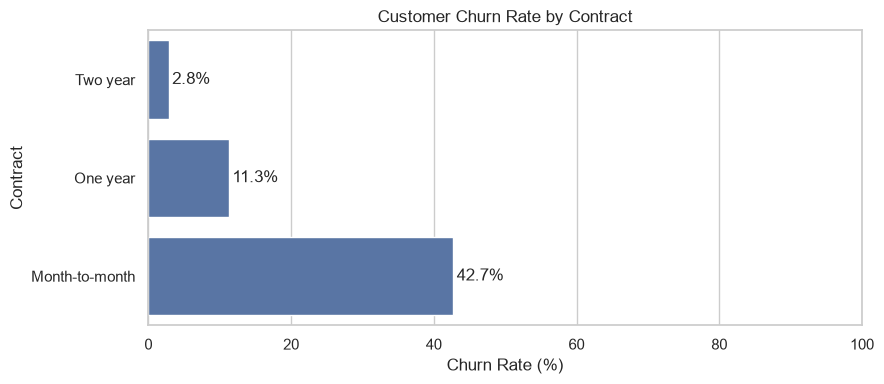

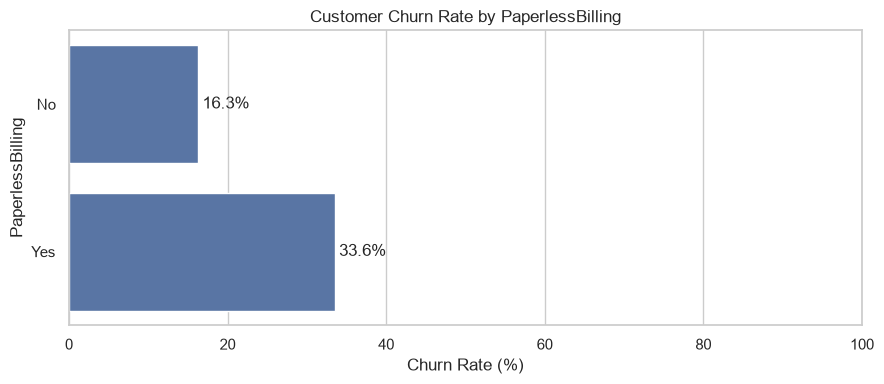

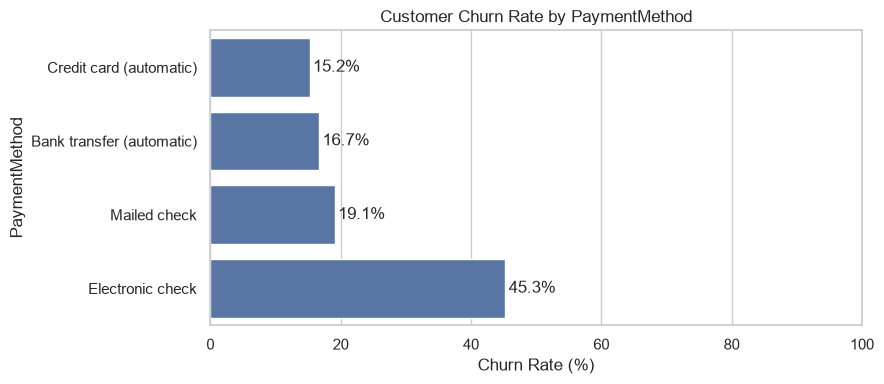

In [18]:
categorical_features = df.select_dtypes(include='object').columns.tolist()

categorical_features.remove('customerID')
categorical_features.remove('Churn')

for feature in categorical_features:

    churn_rates = (
        df.groupby(feature, observed=False)['Churn']
        .apply(lambda x: (x == 'Yes').mean() * 100)
        .sort_values()
    )

    plt.figure(figsize=(9, max(4, len(churn_rates) * 0.6)))

    sns.barplot(
        x=churn_rates.values,
        y=churn_rates.index
    )

    plt.title(f'Customer Churn Rate by {feature}')
    plt.xlabel('Churn Rate (%)')
    plt.ylabel(feature)
    plt.xlim(0, 100)

    for index, value in enumerate(churn_rates.values):
        plt.text(value + 0.5, index, f'{value:.1f}%', va='center')

    plt.tight_layout()
    plt.show()

### 9.2 Categorical Feature Analysis Findings

The categorical analysis highlights several patterns in this dataset:

- Month-to-month contracts have a higher churn rate (42.71%) than one-year (11.27%) and two-year contracts (2.83%).
- Fiber-optic internet customers show a higher churn rate (41.89%) than DSL customers (18.96%).
- Customers without online security and technical support show higher churn rates.
- Electronic-check users have the highest churn rate (45.29%) among the listed payment methods.
- Gender and phone service show comparatively small differences in churn rates.

These are descriptive associations, not evidence that any individual feature causes churn. The models will evaluate the combined predictive value of the available features.

### 9.3 Numerical Feature Analysis

Compare numerical feature summaries across churn categories. Mean, median, and standard deviation help describe differences in central tendency and variability.

In [19]:
numerical_features = ['tenure', 'MonthlyCharges', 'TotalCharges']

for feature in numerical_features:
    print(f"\nChurn Statistics for {feature}:")

    display(
        df.groupby('Churn')[feature]
        .agg(['mean', 'median', 'std'])
        .round(2)
    )


Churn Statistics for tenure:


,mean,median,std
Churn,,,
No,37.57,38.0,24.11
Yes,17.98,10.0,19.53



Churn Statistics for MonthlyCharges:


,mean,median,std
Churn,,,
No,61.27,64.43,31.09
Yes,74.44,79.65,24.67



Churn Statistics for TotalCharges:


,mean,median,std
Churn,,,
No,2555.34,1683.60,2329.46
Yes,1531.80,703.55,1890.82


### 9.4 Numerical Feature Distributions by Churn

Use boxplots to compare numerical feature distributions for customers who churned and those who remained.

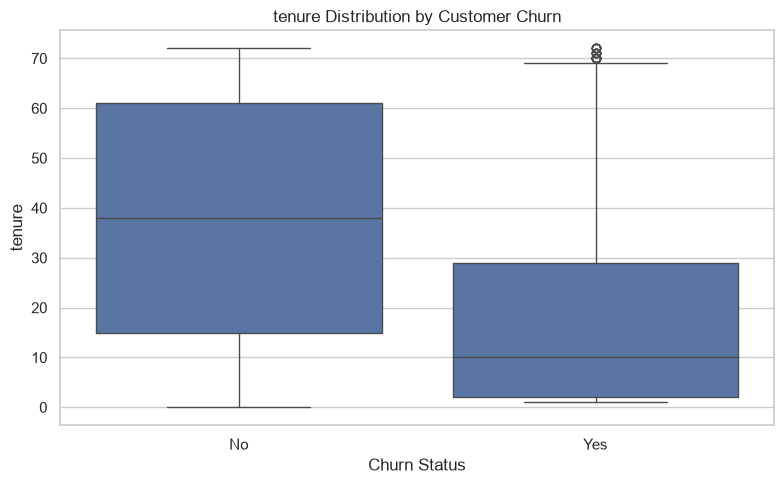

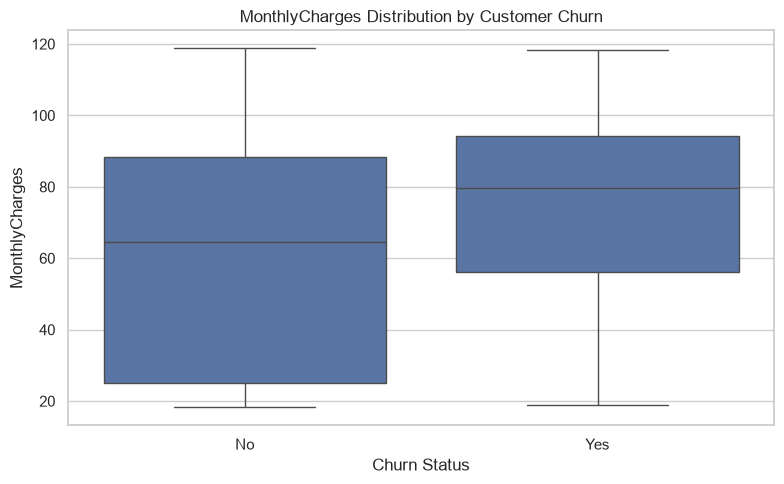

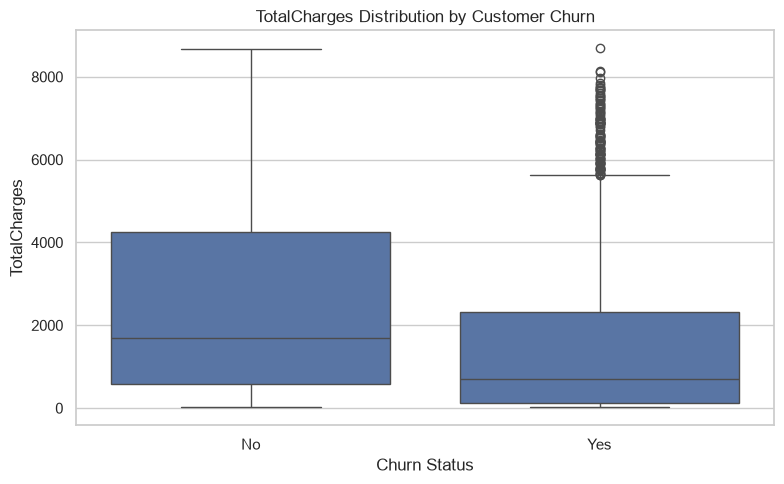

In [20]:
for feature in numerical_features:
    plt.figure(figsize=(8, 5))

    sns.boxplot(data=df, x='Churn', y=feature)

    plt.title(f'{feature} Distribution by Customer Churn')
    plt.xlabel('Churn Status')
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

### 9.5 Numerical Feature Analysis Findings

The numerical analysis shows differences between churned and retained customers:

- Churned customers have lower average tenure (17.98 months) than retained customers (37.57 months).
- Churned customers have higher average monthly charges (74.44) than retained customers (61.27).
- Churned customers have lower average total charges (1531.80) than retained customers (2555.34), which may partly reflect their shorter tenure.

These patterns suggest that tenure and billing variables may provide useful predictive information.

### 9.6 Correlation Analysis of Numerical Features

Use a correlation heatmap to examine the direction and strength of relationships between numerical variables. Correlation can indicate overlapping information, but it does not establish causation.

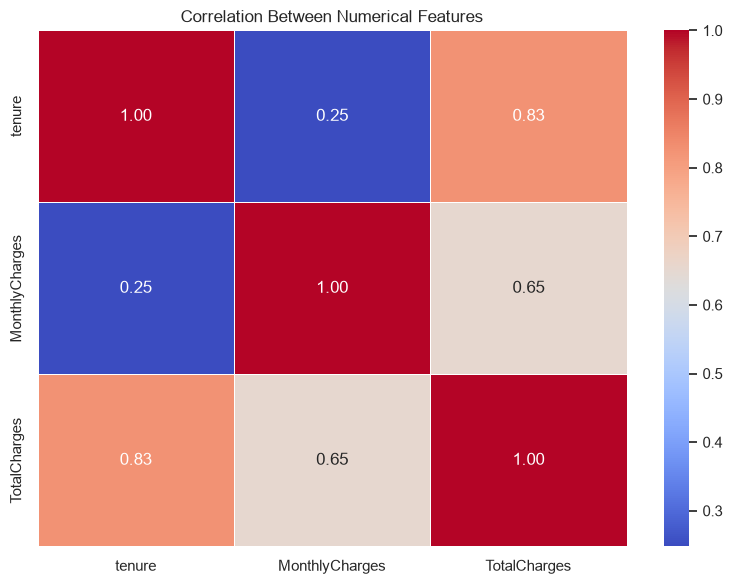

In [21]:
plt.figure(figsize=(8, 6))

correlation_matrix = df[
    ['tenure', 'MonthlyCharges', 'TotalCharges']
].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Between Numerical Features')
plt.tight_layout()
plt.show()

### 9.7 Feature Selection Decision

Based on the exploratory analysis:

- Contract type, tenure, internet service, payment method, and support services show notable associations with churn.
- Gender and phone service show smaller differences when examined individually.
- Numerical variables such as tenure and monthly charges also differ across churn categories.

All 19 available predictor features are retained initially. Features with weak individual relationships may still contribute useful information in combination with other variables. Predictive usefulness is assessed through model evaluation.

### 9.8 Feature Engineering

Create two simple features that may help the models capture customer behaviour:

- `TotalServices`: counts how many listed optional services a customer uses.
- `TenureGroup`: groups customer tenure into four understandable ranges.

These features are created before splitting the data. The original feature columns are kept for now, except for the features explicitly removed in the next step.

In [22]:
# Count the number of services marked as "Yes"
service_columns = [
    'PhoneService',
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

df['TotalServices'] = df[service_columns].eq('Yes').sum(axis=1)

# Group customers by tenure
df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 24, 48, 72],
    labels=['0-12 months', '13-24 months', '25-48 months', '49-72 months']
)

display(df[['tenure', 'TenureGroup', 'TotalServices']].head())


,tenure,TenureGroup,TotalServices
0,1,0-12 months,1
1,34,25-48 months,3
2,2,0-12 months,3
3,45,25-48 months,3
4,2,0-12 months,1


### 9.9 Removing Unnecessary Features

Remove features that are not useful enough to retain in this initial model:

- `customerID`: unique identifier; it is not a customer-behaviour feature.
- `gender`: the initial exploratory analysis showed relatively small churn-rate differences.
- `PhoneService`: its service information is partly represented in the engineered `TotalServices` feature.

The target variable `Churn` is kept separately. All remaining original features and the two engineered features are passed to the models.

## 10. Preparing Features and Target

Prepare the selected feature set for supervised learning:

- Remove `customerID`, `gender`, and `PhoneService` from the input features.
- Keep the two engineered features, `TotalServices` and `TenureGroup`.
- Set `Churn` as the target variable.

The resulting feature matrix is used for the train-test split and model development.

In [23]:
# Separate input features and target variable

X = df.drop(columns=['customerID', 'gender', 'PhoneService', 'Churn'])
y = df['Churn']

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nSelected Features:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

Feature Shape: (7043, 19)
Target Shape: (7043,)

Selected Features:
['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'TotalServices', 'TenureGroup']

Target Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


## 11. Train-Test Split

Split the dataset into training and testing subsets.

- Use 80% of the data for training and 20% for final testing.
- Apply stratification to preserve the target-class proportions in both subsets.
- Set a fixed random state to make the split reproducible.

The test set is held out for final evaluation and is not used to fit the models.

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Define stratified cross-validation for model comparison
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (5634, 19)
Testing Features: (1409, 19)
Training Target: (5634,)
Testing Target: (1409,)


## 12. Data Preprocessing

Numerical and categorical variables require different preprocessing operations.

- Numerical features: median imputation and standardization.
- Categorical features: most-frequent-value imputation and one-hot encoding.
- Combine the transformations using a preprocessing pipeline.

Keeping preprocessing inside the model pipeline helps prevent data leakage by fitting transformations on training data only.

In [25]:
# Identify numerical and categorical columns

numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

print("\nNumber of Numerical Features:", len(numeric_features))
print("Number of Categorical Features:", len(categorical_features))

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'TotalServices']

Categorical Features: ['Partner', 'Dependents', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of Numerical Features: 5
Number of Categorical Features: 13


C:\Users\sajja\AppData\Local\Temp\ipykernel_2104\3289485172.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


### 12.1 Numerical and Categorical Preprocessing

Create separate preprocessing pipelines for each feature type.

- Median imputation handles missing numerical values.
- StandardScaler standardizes numerical variables.
- Most-frequent imputation handles missing categorical values.
- OneHotEncoder converts categorical values into numerical features.

In [26]:
# Numerical preprocessing pipeline

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing pipeline

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

### 12.2 Combined Preprocessing with ColumnTransformer

Combine the numerical and categorical transformations using `ColumnTransformer`. This applies the appropriate preprocessing steps to each selected group of columns.

In [27]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 13. Baseline Model

Establish a simple reference point using a `DummyClassifier` with the `most_frequent` strategy. This model predicts the majority class without learning relationships from customer features.

A useful machine learning model should provide value beyond this baseline.

### 13.1 Training the Baseline Model

Fit the majority-class baseline on the training data and generate predictions for the test set.

In [28]:
# Create and train the baseline model

baseline_model = DummyClassifier(strategy='most_frequent')

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print("Baseline Model Accuracy:", round(baseline_accuracy * 100, 2), "%")

Baseline Model Accuracy: 73.46 %


### 13.2 Baseline Performance Analysis

The baseline model achieved 73.46% accuracy by predicting every customer as non-churn.

- It correctly classified all 1,035 non-churning customers in the test set.
- It failed to identify any of the 374 customers who actually churned.
- Precision and recall for the churn class (`Yes`) are both 0.00.
- The confusion matrix shows why accuracy alone can be misleading for an imbalanced classification problem.

This baseline demonstrates why models must be evaluated on their ability to identify churners, not only on overall accuracy.

## 14. Machine Learning Model Selection

Two classification algorithms are selected for customer churn prediction:

- **Logistic Regression:** a linear classification algorithm commonly used for binary classification.
- **Random Forest:** an ensemble algorithm that combines predictions from multiple decision trees.

Both models use the same preprocessing pipeline to ensure a consistent comparison.

In [29]:
logistic_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

random_forest_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE
    ))
])

print("Both machine learning models created successfully!")

Both machine learning models created successfully!


## 15. Model Comparison Using Cross-Validation

Compare the baseline and candidate models using five-fold stratified cross-validation on the training data.

- Stratified folds preserve the class distribution in each fold.
- Mean cross-validation accuracy is used for the initial comparison.
- Standard deviation describes variation across folds.

Cross-validation is performed on the training data; the held-out test set remains reserved for final evaluation.

In [30]:
models = {
    'Baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': logistic_pipeline,
    'Random Forest': random_forest_pipeline
}

model_results = []

for model_name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='accuracy'
    )

    model_results.append({
        'Model': model_name,
        'Mean CV Accuracy': scores.mean(),
        'Standard Deviation': scores.std()
    })

model_comparison = pd.DataFrame(model_results)

model_comparison['Mean CV Accuracy'] = (
    model_comparison['Mean CV Accuracy'] * 100
).round(2)

model_comparison['Standard Deviation'] = (
    model_comparison['Standard Deviation'] * 100
).round(2)

display(model_comparison.sort_values(
    by='Mean CV Accuracy',
    ascending=False
).reset_index(drop=True))

,Model,Mean CV Accuracy,Standard Deviation
0,Logistic Regression,80.32,1.26
1,Random Forest,79.00,1.08
2,Baseline,73.46,0.01


### 15.1 Cross-Validation Results

The cross-validation results show that both machine learning models outperform the majority-class baseline on mean accuracy.

| Model | Mean CV Accuracy | Standard Deviation |
|---|---:|---:|
| Logistic Regression | **80.32%** | 1.26% |
| Random Forest | 79.00% | 1.08% |
| Baseline | 73.46% | 0.01% |

Logistic Regression achieved the highest mean cross-validation accuracy and is selected as the leading candidate for further evaluation. The final decision also considers performance on the unseen test set and the ability to identify customers who churn.

## 16. Model Training

Fit Logistic Regression and Random Forest using the training data. The held-out test data is not used during fitting.

In [31]:
logistic_pipeline.fit(X_train, y_train)
random_forest_pipeline.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


## 17. Model Evaluation on the Test Set

Evaluate both fitted models on the unseen test set.

- **Accuracy:** overall proportion of correct predictions.
- **Precision:** of the customers predicted to churn, the proportion who actually churned.
- **Recall:** of the customers who actually churned, the proportion correctly identified.
- **Confusion matrix:** counts of correct and incorrect predictions for each class.

Because identifying churners is important for retention, precision and recall for the `Yes` class deserve particular attention.

### 17.1 Generating Predictions and Comparing Metrics

Generate predictions from both fitted models and calculate accuracy, precision, and recall for the churn class.

In [32]:
logistic_predictions = logistic_pipeline.predict(X_test)
random_forest_predictions = random_forest_pipeline.predict(X_test)

evaluation_results = []

for model_name, predictions in [
    ('Logistic Regression', logistic_predictions),
    ('Random Forest', random_forest_predictions)
]:
    evaluation_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, pos_label='Yes'),
        'Recall': recall_score(y_test, predictions, pos_label='Yes')
    })

evaluation_df = pd.DataFrame(evaluation_results)

for column in ['Accuracy', 'Precision', 'Recall']:
    evaluation_df[column] = (evaluation_df[column] * 100).round(2)

display(evaluation_df)

,Model,Accuracy,Precision,Recall
0,Logistic Regression,80.55,65.72,55.88
1,Random Forest,78.07,61.09,47.86


### 17.2 Test-Set Performance Comparison

The test-set evaluation shows that Logistic Regression performs better than Random Forest on the reported metrics.

| Model | Accuracy | Churn Precision | Churn Recall |
|---|---:|---:|---:|
| Logistic Regression | **80.55%** | **65.72%** | **55.88%** |
| Random Forest | 78.07% | 61.09% | 47.86% |

- Both models exceed the baseline accuracy of 73.46%.
- Logistic Regression achieves higher accuracy, precision, and recall.
- Logistic Regression identifies a larger proportion of actual churners, although it still misses 44.12% of them.

Based on these results, Logistic Regression is the better-performing model among the two tested. Accuracy alone is not sufficient; churn recall remains an important area for improvement.

### 17.3 Confusion Matrices

Compare the confusion matrices for Logistic Regression and Random Forest to examine their correct predictions, false positives, and false negatives.

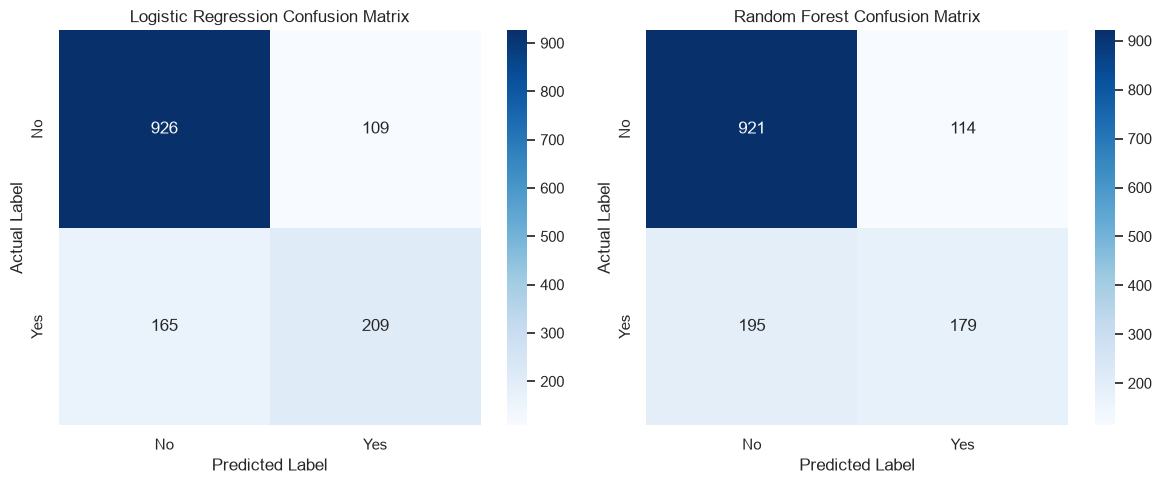

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, model_name, predictions in [
    (axes[0], 'Logistic Regression', logistic_predictions),
    (axes[1], 'Random Forest', random_forest_predictions)
]:
    cm = confusion_matrix(y_test, predictions, labels=['No', 'Yes'])
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No', 'Yes'],
        yticklabels=['No', 'Yes'],
        ax=ax
    )
    ax.set_title(f'{model_name} Confusion Matrix')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

### 17.4 Classification Reports

Classification reports provide class-level precision, recall, and F1-score for both churn categories.

- `No` represents customers who remain with the company.
- `Yes` represents customers who churn.
- F1-score is the harmonic mean of precision and recall.

In [34]:
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    logistic_predictions,
    zero_division=0
))

print("\nRANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    random_forest_predictions,
    zero_division=0
))

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

          No       0.83      0.89      0.86      1035
         Yes       0.61      0.48      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409



### 17.5 Classification Report Findings

The classification reports provide further detail about model performance.

- Logistic Regression achieved an F1-score of **0.60** for the churn class, compared with **0.54** for Random Forest.
- Logistic Regression identified **55.88%** of actual churn cases, while Random Forest identified **47.86%**.
- Both models identify non-churning customers more effectively than churning customers.

Based on the evaluated metrics, Logistic Regression is selected as the final model. Its missed churn cases are examined in the next section.

## 18. Error Analysis

Examine incorrect predictions made by the selected Logistic Regression model.

- **False positive:** a customer is predicted to churn but actually stays.
- **False negative:** a customer is predicted to stay but actually churns.

False negatives are especially relevant to retention because they represent customers who may leave without being identified by the model.

In [35]:
error_analysis = X_test.copy()

error_analysis['Actual Churn'] = y_test
error_analysis['Predicted Churn'] = logistic_predictions

incorrect_predictions = error_analysis[
    error_analysis['Actual Churn'] !=
    error_analysis['Predicted Churn']
].copy()

false_positives = incorrect_predictions[
    (incorrect_predictions['Actual Churn'] == 'No') &
    (incorrect_predictions['Predicted Churn'] == 'Yes')
]

false_negatives = incorrect_predictions[
    (incorrect_predictions['Actual Churn'] == 'Yes') &
    (incorrect_predictions['Predicted Churn'] == 'No')
]

print("Total Incorrect Predictions:", len(incorrect_predictions))
print("False Positives:", len(false_positives))
print("False Negatives:", len(false_negatives))

display(incorrect_predictions.head(10))

Total Incorrect Predictions: 274
False Positives: 109
False Negatives: 165


,SeniorCitizen,Partner,Dependents,tenure,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,TotalServices,TenureGroup,Actual Churn,Predicted Churn
2280,1,No,No,8,Yes,Fiber optic,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,5,0-12 months,No,Yes
5748,0,No,No,21,Yes,Fiber optic,No,Yes,No,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),99.85,1992.55,5,13-24 months,No,Yes
1639,1,No,No,17,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,45.05,770.60,1,13-24 months,Yes,No
2136,0,No,Yes,15,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Electronic check,91.00,1430.05,4,13-24 months,No,Yes
950,1,No,No,2,No,DSL,No,No,No,No,No,No,Month-to-month,No,Mailed check,44.95,85.15,1,0-12 months,Yes,No
2488,0,No,No,31,No,DSL,No,No,Yes,Yes,No,No,Month-to-month,Yes,Electronic check,55.25,1715.65,3,25-48 months,Yes,No
2519,0,Yes,No,2,Yes,Fiber optic,No,No,Yes,No,Yes,No,Month-to-month,Yes,Electronic check,91.45,171.45,4,0-12 months,No,Yes
3510,0,No,No,8,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,75.25,576.70,2,0-12 months,No,Yes
523,0,No,No,23,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,No,Bank transfer (automatic),75.60,1758.60,2,13-24 months,Yes,No
5086,0,No,No,45,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Electronic check,20.40,930.45,1,25-48 months,Yes,No


### 18.1 Error Analysis Findings

The selected Logistic Regression model produced 274 incorrect predictions on the test set:

- **109 false positives:** customers predicted to churn who actually stayed.
- **165 false negatives:** customers predicted to stay but who actually churned.

False negatives are particularly important because they represent missed opportunities to identify customers who may need retention attention. Some incorrectly classified records share characteristics associated with churn, such as month-to-month contracts, shorter tenure, fiber-optic internet, or electronic-check payments. These overlapping patterns illustrate that individual outcomes are not determined by one characteristic alone.

The results suggest that further work could focus on improving churn recall and reducing false negatives.

## 19. Conclusion

This project applied supervised machine learning to predict customer churn using the IBM Telco Customer Churn dataset.

### Key Findings

- The dataset contains **7,043 customer records** and **19 model input features** after feature engineering and feature selection.
- Exploratory analysis identified associations between churn and contract type, tenure, internet service, and payment method.
- Logistic Regression achieved the highest mean cross-validation accuracy (**80.32%**).
- On the unseen test set, Logistic Regression achieved **80.55% accuracy**, **65.72% precision**, and **55.88% recall** for the churn class.
- Logistic Regression outperformed Random Forest on the reported test metrics.

### Final Remarks

The results demonstrate how machine learning can support customer-retention efforts by identifying customers who may be at risk of leaving. However, the selected model still misses a notable number of actual churners. Future improvements should investigate recall-focused evaluation, decision-threshold tuning, class-imbalance techniques, and additional model comparisons.

The results describe predictive patterns in this dataset and should not be interpreted as proof that any customer characteristic causes churn.

## 20. Exporting Results for the Interactive Dashboard

Export the fitted model pipelines and evaluation outputs generated in this notebook. The Streamlit dashboard reads these files for visualization and individual predictions; it does not retrain the models or independently calculate evaluation metrics.

Run this section after completing the notebook workflow. The `artifacts/` directory will be created beside the notebook folder.

In [36]:
# Export the notebook's fitted models and evaluation results for the Streamlit dashboard
# The dashboard loads these artifacts; it does not retrain or recalculate the ML workflow.

from pathlib import Path
import json
import joblib
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix
)

ARTIFACT_DIR = Path("../artifacts")
MODEL_DIR = ARTIFACT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the exact fitted pipelines produced in this notebook.
joblib.dump(logistic_pipeline, MODEL_DIR / "logistic_regression.joblib")
joblib.dump(random_forest_pipeline, MODEL_DIR / "random_forest.joblib")

# Save test-set predictions from the already-fitted models.
test_predictions = pd.DataFrame({
    "Actual Churn": y_test.to_numpy(),
    "Logistic Regression Prediction": logistic_predictions,
    "Random Forest Prediction": random_forest_predictions
}, index=X_test.index)
test_predictions.insert(0, "customerID", df.loc[X_test.index, "customerID"].to_numpy())

# Save probabilities when supported, for ROC analysis in the dashboard.
test_predictions["Logistic Regression Churn Probability"] = (
    logistic_pipeline.predict_proba(X_test)[:, list(logistic_pipeline.classes_).index("Yes")]
)
test_predictions["Random Forest Churn Probability"] = (
    random_forest_pipeline.predict_proba(X_test)[:, list(random_forest_pipeline.classes_).index("Yes")]
)
test_predictions.to_csv(ARTIFACT_DIR / "test_predictions.csv", index=False)

# Save the existing cross-validation results (already calculated above).
model_comparison.to_csv(ARTIFACT_DIR / "cross_validation_metrics.csv", index=False)

# Build a complete metric summary from the notebook's existing test predictions.
metric_rows = []
classification_reports = {}
confusion_matrices = {}
for model_name, predictions, fitted_model in [
    ("Logistic Regression", logistic_predictions, logistic_pipeline),
    ("Random Forest", random_forest_predictions, random_forest_pipeline),
    ("Baseline", baseline_predictions, baseline_model)
]:
    probability = None
    if hasattr(fitted_model, "predict_proba"):
        probability = fitted_model.predict_proba(X_test)[:, list(fitted_model.classes_).index("Yes")]

    row = {
        "Model": model_name,
        "Accuracy": float(accuracy_score(y_test, predictions)),
        "Balanced Accuracy": float(balanced_accuracy_score(y_test, predictions)),
        "Churn Precision": float(precision_score(y_test, predictions, pos_label="Yes", zero_division=0)),
        "Churn Recall": float(recall_score(y_test, predictions, pos_label="Yes", zero_division=0)),
        "Churn F1-score": float(f1_score(y_test, predictions, pos_label="Yes", zero_division=0)),
        "ROC-AUC": float(roc_auc_score((y_test == "Yes").astype(int), probability)) if probability is not None else None
    }
    metric_rows.append(row)
    classification_reports[model_name] = classification_report(
        y_test, predictions, labels=["No", "Yes"], output_dict=True, zero_division=0
    )
    confusion_matrices[model_name] = confusion_matrix(
        y_test, predictions, labels=["No", "Yes"]
    ).tolist()

pd.DataFrame(metric_rows).to_csv(ARTIFACT_DIR / "test_metrics.csv", index=False)

with open(ARTIFACT_DIR / "classification_reports.json", "w", encoding="utf-8") as file:
    json.dump(classification_reports, file, indent=2)
with open(ARTIFACT_DIR / "confusion_matrices.json", "w", encoding="utf-8") as file:
    json.dump(confusion_matrices, file, indent=2)

# Export the notebook's existing Logistic Regression error analysis.
error_export = incorrect_predictions.copy()
error_export.insert(0, "customerID", df.loc[error_export.index, "customerID"].to_numpy())
error_export.to_csv(ARTIFACT_DIR / "error_analysis.csv", index=False)

# Keep feature order and positive-class meaning explicit for inference.
metadata = {
    "target": "Churn",
    "positive_class": "Yes",
    "feature_columns": X.columns.tolist(),
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "random_state": int(RANDOM_STATE),
    "selected_model": "Logistic Regression"
}
with open(ARTIFACT_DIR / "metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

print(f"Dashboard artifacts exported successfully to: {ARTIFACT_DIR.resolve()}")
print("Saved: both trained pipelines, test metrics, cross-validation results,")
print("classification reports, confusion matrices, predictions, and error analysis.")


Dashboard artifacts exported successfully to: C:\Users\sajja\Documents\PSEB BOOTCAMP\Project\github\customer-churn-prediction\artifacts
Saved: both trained pipelines, test metrics, cross-validation results,
classification reports, confusion matrices, predictions, and error analysis.
